In [3]:
# ДЗ
# 1. Подберите парамтеры алгоритма разрастания регионов так, чтобы был выделен весь участок газона.
# 2. Реализуйте вычисление критерия однородности, отличного от представленного. Сравните результаты.
# 3. Применить алгоритм сегментации watershed+distance transform для задачи подсчета пальмовых деревьев.

In [4]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import math


In [5]:
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

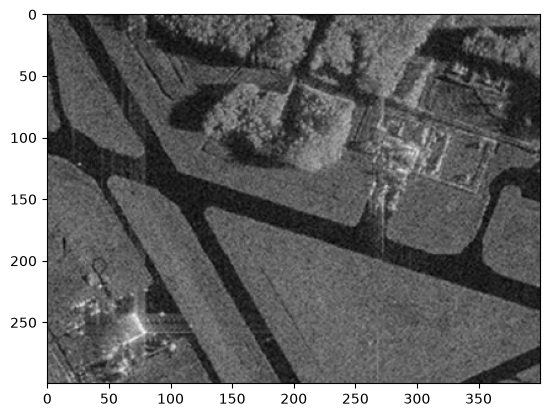

In [6]:
plt.imshow(image_gray, cmap="gray")

In [7]:
def homo_average(img, mask, point, T):
    av_val = cv2.mean(img, mask)[0]

    if abs(av_val - img[point]) <= T:
        return True

    return False

In [8]:
def region_growing(image, seed_point, homo_fun, r, T):
    mask = np.zeros(image.shape, np.uint8)
    mask[seed_point] = 1
    queue = [seed_point]
    while queue:
        new_queue = []
        for (i, j) in queue:
            for di in range(-r, r + 1):
                for dj in range(-r, r + 1):
                    ni, nj = i + di, j + dj
                    if not (0 <= ni < image.shape[0] and 0 <= nj < image.shape[1]):
                        continue
                    if mask[ni, nj] != 0:
                        continue
                    if homo_fun(image, mask, (ni, nj), T):
                        mask[ni, nj] = 1
                        new_queue.append((ni, nj))
        print(len(new_queue))
        queue = new_queue

    return mask * 255

In [9]:
seed_point = (250, 250)

for T in [5, 10, 15, 20, 25, 30, 40, 50]:
    mask = region_growing(image_gray, seed_point, homo_average, 2, T)
    print("----  T =", T, " pixels =", np.count_nonzero(mask))

12
14
42
44
45
77
79
91
92
102
110
135
143
118
142
141
183
179
191
168
191
200
219
218
236
220
214
204
201
215
183
165
122
106
104
103
99
121
111
97
123
109
111
112
104
81
85
72
72
75
87
83
84
83
74
78
88
67
51
64
58
52
28
30
22
28
25
30
32
24
19
12
19
16
12
8
1
0
----  T = 5  pixels = 7557
21
35
80
102
110
135
164
177
202
238
273
297
298
319
333
356
383
398
445
453
484
512
522
525
447
378
389
363
382
340
332
313
287
287
248
254
242
228
245
249
228
213
215
201
184
177
193
196
163
147
143
152
132
141
135
129
113
118
99
69
64
58
56
50
59
69
56
48
49
45
36
41
40
31
19
0
----  T = 10  pixels = 15716
22
49
82
112
138
167
196
222
245
289
326
349
380
380
421
455
475
544
541
571
597
636
636
619
530
447
449
442
423
412
398
379
370
361
331
334
297
293
296
286
281
277
257
247
230
215
216
225
203
193
172
184
174
174
162
157
138
138
123
100
91
76
79
79
76
80
75
66
64
60
56
56
52
49
25
0
----  T = 15  pixels = 19351
24
56
86
116
145
184
207
238
271
305
341
371
402
422
462
490
521
560
583
615
643
676

In [10]:
for r in [1, 2, 3, 4]:
    mask = region_growing(image_gray, seed_point, homo_average, r, 20)
    print("----  r =", r, " pixels =", np.count_nonzero(mask))

8
16
24
32
40
46
53
63
70
75
87
96
100
107
115
123
129
142
148
157
168
173
183
188
198
204
209
211
226
234
241
250
261
260
278
282
290
293
302
313
317
326
336
339
343
341
338
336
334
241
244
237
237
236
231
230
225
219
216
217
211
212
205
200
201
198
195
190
177
179
186
176
172
162
160
160
164
159
154
155
150
144
141
142
139
134
133
133
129
129
124
118
118
118
119
115
115
112
107
104
103
92
99
95
93
94
93
93
88
87
84
79
78
76
75
71
68
67
60
54
54
51
49
45
42
45
45
45
43
42
43
41
41
38
37
36
36
35
34
33
32
33
31
30
30
28
29
29
27
0
----  r = 1  pixels = 20832
24
56
86
116
145
184
207
238
271
305
341
371
402
422
462
490
521
560
583
615
643
676
685
674
575
482
473
460
444
433
423
405
399
385
359
359
334
321
323
309
294
284
271
266
258
242
236
234
227
211
195
194
187
186
175
163
154
146
135
114
106
93
87
90
85
84
79
73
71
67
65
61
58
58
27
0
----  r = 2  pixels = 20838
48
118
186
258
323
395
473
544
613
673
751
820
885
956
1018
1018
817
711
685
652
628
599
562
541
494
488
459
428
405
391
3

In [11]:
seed_point = (250, 250)
mask = region_growing(image_gray, seed_point, homo_average, 2, 20)

24
56
86
116
145
184
207
238
271
305
341
371
402
422
462
490
521
560
583
615
643
676
685
674
575
482
473
460
444
433
423
405
399
385
359
359
334
321
323
309
294
284
271
266
258
242
236
234
227
211
195
194
187
186
175
163
154
146
135
114
106
93
87
90
85
84
79
73
71
67
65
61
58
58
27
0


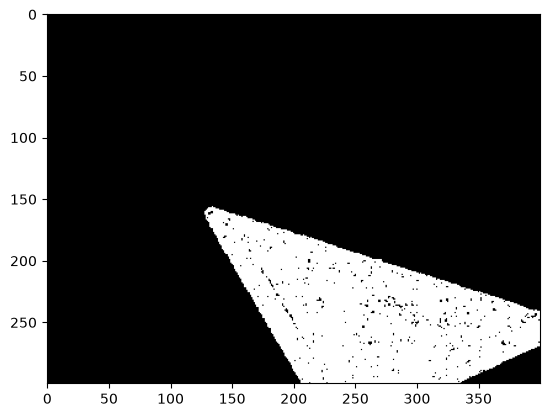

In [12]:
plt.imshow(mask, cmap="gray")

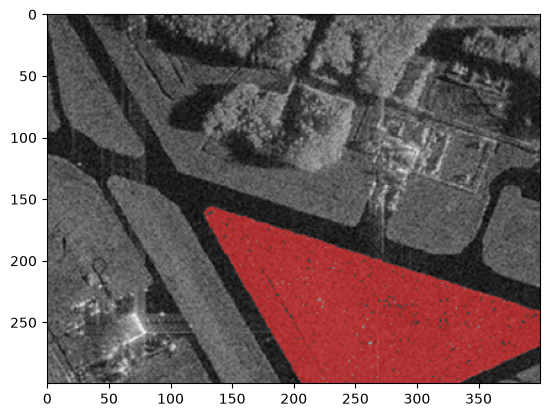

In [13]:
plt.imshow(image_gray, cmap="gray")
plt.imshow(np.ma.masked_where(mask == 0, mask), cmap="autumn", alpha=0.5)

In [14]:
# Задание 2
def homo_std(img, mask, point, T):
    mean, std = cv2.meanStdDev(img, mask=mask)
    mu = mean[0, 0]
    sigma = std[0, 0]
    n = np.count_nonzero(mask)
    v = float(img[point])
    n_new = n + 1
    mu_new = (n * mu + v) / n_new
    var_new = (n * sigma ** 2 + n * (mu - mu_new) ** 2 + (v - mu_new) ** 2) / n_new

    if np.sqrt(var_new) <= T:
        return True

    return False

In [15]:
def homo_median(img, mask, point, T):
    hist = cv2.calcHist([img], [0], mask, [256], [0, 256]).ravel()
    total = int(hist.sum())
    cdf = 0
    med = 0
    for i in range(256):
        cdf += int(hist[i])
        if cdf * 2 >= total:
            med = i
            break

    if abs(med - int(img[point])) <= T:
        return True

    return False

In [16]:
seed_point = (250, 250)

mask_avg    = region_growing(image_gray, seed_point, homo_average, 2, 20)
mask_std    = region_growing(image_gray, seed_point, homo_std,     2, 15)
mask_median = region_growing(image_gray, seed_point, homo_median,  2, 20)

print("average:", np.count_nonzero(mask_avg))
print("std    :", np.count_nonzero(mask_std))
print("median :", np.count_nonzero(mask_median))

24
56
86
116
145
184
207
238
271
305
341
371
402
422
462
490
521
560
583
615
643
676
685
674
575
482
473
460
444
433
423
405
399
385
359
359
334
321
323
309
294
284
271
266
258
242
236
234
227
211
195
194
187
186
175
163
154
146
135
114
106
93
87
90
85
84
79
73
71
67
65
61
58
58
27
0
24
56
88
120
152
184
216
248
280
312
344
376
408
440
472
504
536
568
600
632
664
696
728
760
691
610
626
642
658
558
506
519
520
527
530
536
539
537
562
560
528
515
503
501
500
496
490
491
483
467
446
466
478
525
544
542
572
560
576
599
605
618
619
600
619
602
608
612
636
651
630
598
597
660
568
489
492
409
369
404
420
470
458
451
425
402
410
402
397
349
396
385
394
346
371
371
371
420
407
436
411
389
412
367
343
397
353
309
231
249
234
284
288
241
271
291
312
274
298
294
287
300
287
301
321
175
130
78
64
80
75
72
73
73
66
85
94
93
116
103
108
106
88
103
150
144
132
130
141
108
128
140
118
112
122
88
93
120
117
104
119
123
79
31
23
16
5
6
1
1
0
23
57
86
116
146
183
207
242
271
307
342
373
401
423
461
492
5

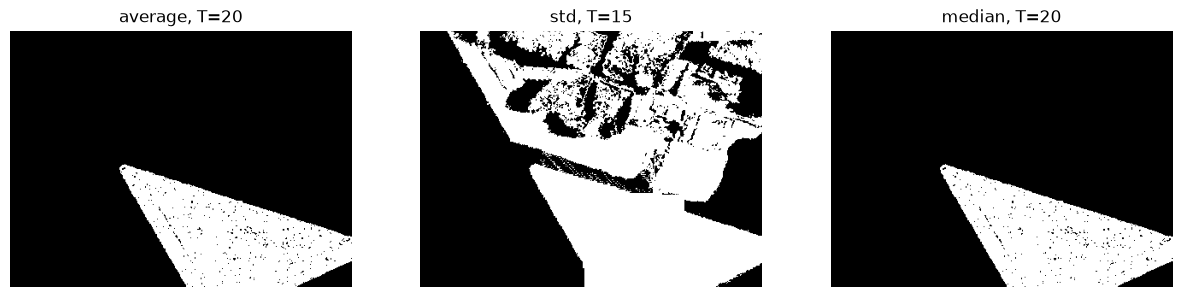

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(mask_avg, cmap="gray");    ax[0].set_title("average, T=20")
ax[1].imshow(mask_std, cmap="gray");    ax[1].set_title("std, T=15")
ax[2].imshow(mask_median, cmap="gray"); ax[2].set_title("median, T=20")
for a in ax:
    a.axis("off")
plt.show()

In [ ]:
# Задание 3
image_palms = cv2.imread('palm_1.jpg')
gray = cv2.cvtColor(image_palms, cv2.COLOR_BGR2GRAY)

blurred = cv2.GaussianBlur(gray, (11, 11), 0)

In [20]:
_, thresh = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

kernel = np.ones((5, 5), np.uint8)
dilated = cv2.dilate(thresh, kernel, iterations=1)
opening = cv2.morphologyEx(dilated, cv2.MORPH_OPEN, kernel, iterations=1)

In [21]:
dist_transform = cv2.distanceTransform(opening, cv2.DIST_L2, 5)

ret, sure_fg = cv2.threshold(dist_transform, 0.3 * dist_transform.max(), 255, 0)
sure_fg = np.uint8(sure_fg)

sure_bg = cv2.dilate(opening, kernel, iterations=1)

unknown = cv2.subtract(sure_bg, sure_fg)

ret, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0

In [22]:
markers = cv2.watershed(image_palms, markers)
image_palms[markers == -1] = [255, 0, 0]

unique_markers = np.unique(markers)
object_markers = [m for m in unique_markers if m != 1 and m != -1]
count = len(object_markers)
print(f"Количество обнаруженных пальм: {count}")

Количество обнаруженных пальм: 85


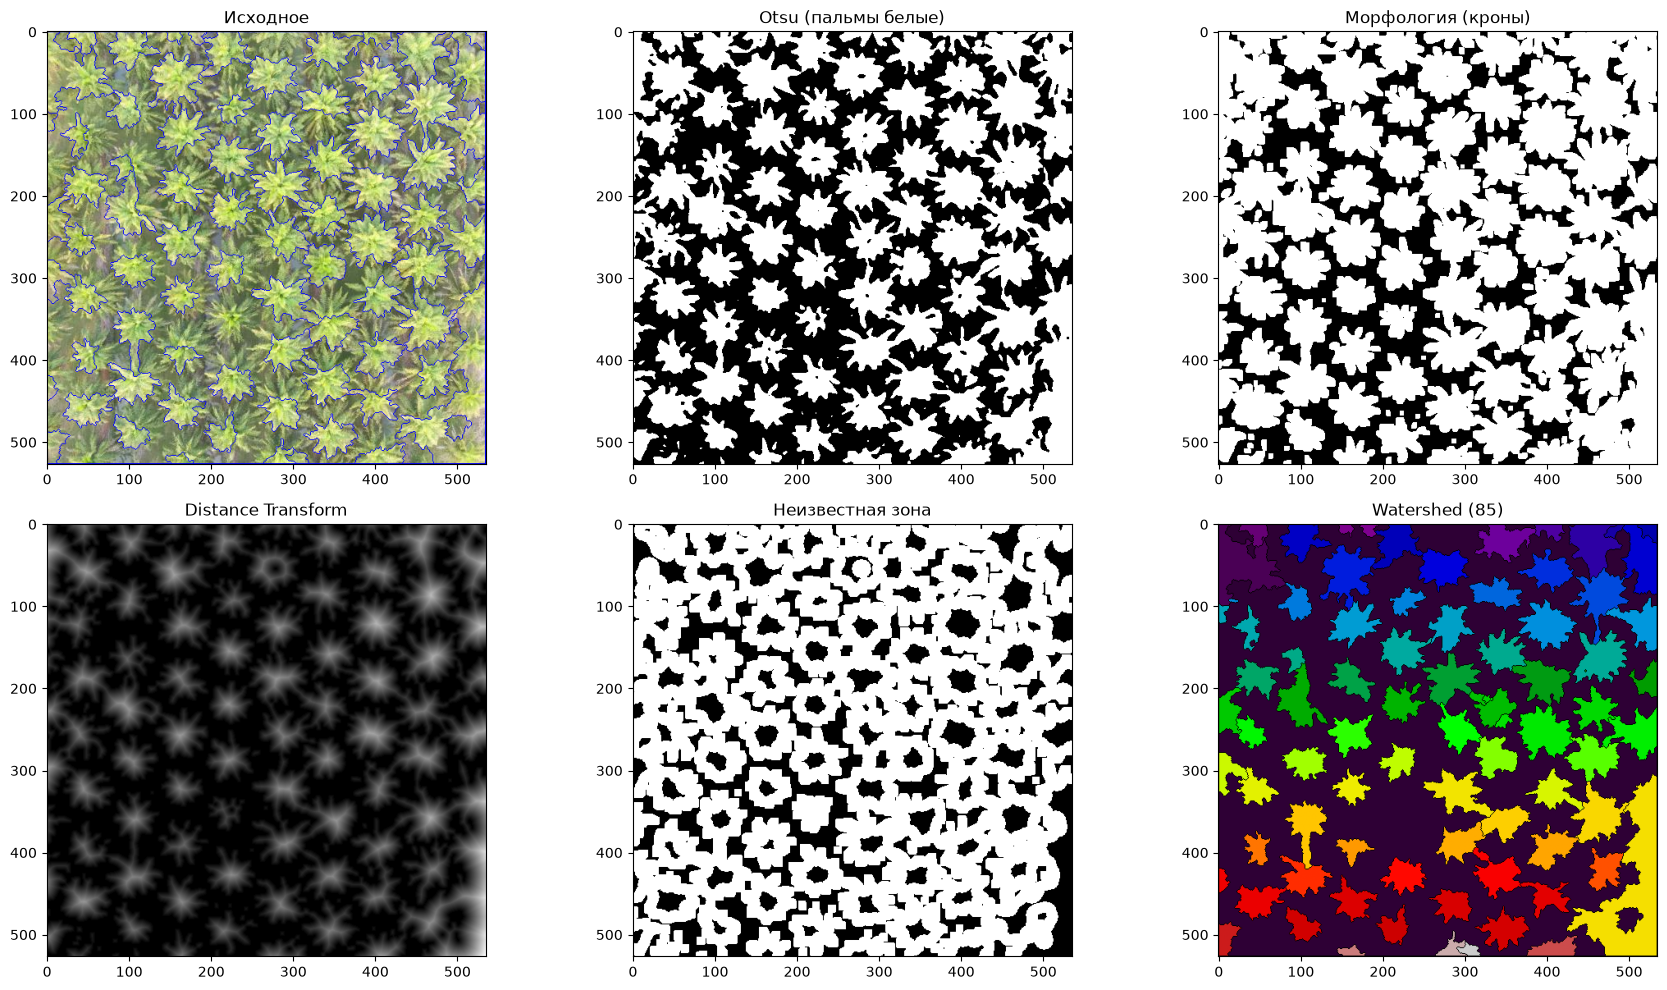

In [23]:
plt.figure(figsize=(18, 10))

plt.subplot(2, 3, 1); plt.imshow(cv2.cvtColor(image_palms, cv2.COLOR_BGR2RGB)); plt.title('Исходное')
plt.subplot(2, 3, 2); plt.imshow(thresh, cmap='gray'); plt.title('Otsu (пальмы белые)')
plt.subplot(2, 3, 3); plt.imshow(opening, cmap='gray'); plt.title('Морфология (кроны)')
plt.subplot(2, 3, 4); plt.imshow(dist_transform, cmap='gray'); plt.title('Distance Transform')
plt.subplot(2, 3, 5); plt.imshow(unknown, cmap='gray'); plt.title('Неизвестная зона')
plt.subplot(2, 3, 6); plt.imshow(markers, cmap='nipy_spectral'); plt.title(f'Watershed ({count})')

plt.tight_layout()
plt.show()